# Basic Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../data/final_merged.csv')

In [34]:
df.head()

,state,year,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,rain,snowfall,weather_code,pressure_msl,...,wind_gusts_10m,shortwave_radiation,direct_radiation,diffuse_radiation,direct_normal_irradiance,sunshine_duration,is_day,date,hour,demand_mw
0,Andhra Pradesh,2017.0,20.4,96.0,23.4,0.0,0.0,0.0,0.0,1014.8,...,9.0,0.0,0.0,0.0,0.0,0.0,0.0,01/01/17,0,5336.69
1,Andhra Pradesh,2017.0,19.7,97.0,22.4,0.0,0.0,0.0,0.0,1014.7,...,7.2,0.0,0.0,0.0,0.0,0.0,0.0,01/01/17,1,5298.24
2,Andhra Pradesh,2017.0,19.2,98.0,21.7,0.0,0.0,0.0,0.0,1014.0,...,7.2,0.0,0.0,0.0,0.0,0.0,0.0,01/01/17,2,5193.17
3,Andhra Pradesh,2017.0,18.8,98.0,21.5,0.0,0.0,0.0,0.0,1013.9,...,6.8,0.0,0.0,0.0,0.0,0.0,0.0,01/01/17,3,5136.10
4,Andhra Pradesh,2017.0,18.4,99.0,20.9,0.0,0.0,0.0,0.0,1013.7,...,6.5,0.0,0.0,0.0,0.0,0.0,0.0,01/01/17,4,5533.07


In [10]:
df.shape

(2629392, 32)

In [9]:

# 1. Create a proper Datetime column from 'date' and 'hour'
# Assuming 'date' is DD/MM/YY based on your sample "01/01/17"
df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['hour'].astype(str) + ':00', format='%d/%m/%y %H:%M')

# 2. Set as index and sort
df = df.set_index('datetime').sort_index()

# 3. Drop redundant columns
df = df.drop(columns=['date', 'hour', 'year', 'state']) # We will recreate better time features

# 4. Check for missing time steps (Crucial for hourly data)
expected_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='H')
missing_hours = expected_range.difference(df.index)
print(f"Missing hourly records: {len(missing_hours)}")

# If there are missing hours, reindex and interpolate
if len(missing_hours) > 0:
    df = df.reindex(expected_range)
    df = df.interpolate(method='time') # Time-based interpolation for weather/demand

Missing hourly records: 0


C:\Users\dipan\AppData\Local\Temp\ipykernel_11008\1547428786.py:12: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  expected_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='H')


## Macro view

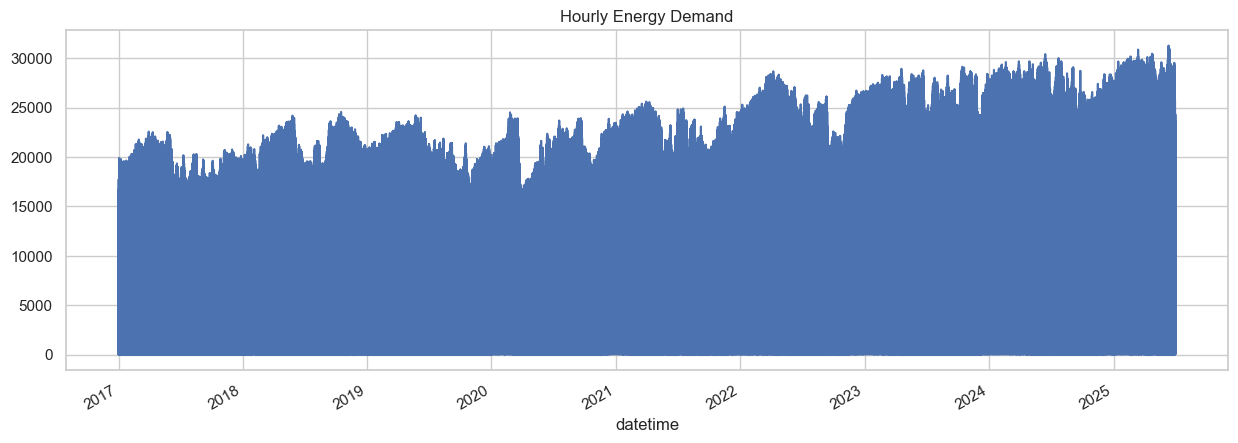

In [36]:
# Plot data to see the daily rhythm
df['demand_mw'].iloc[:].plot(figsize=(15, 5), title='Hourly Energy Demand')
plt.show()

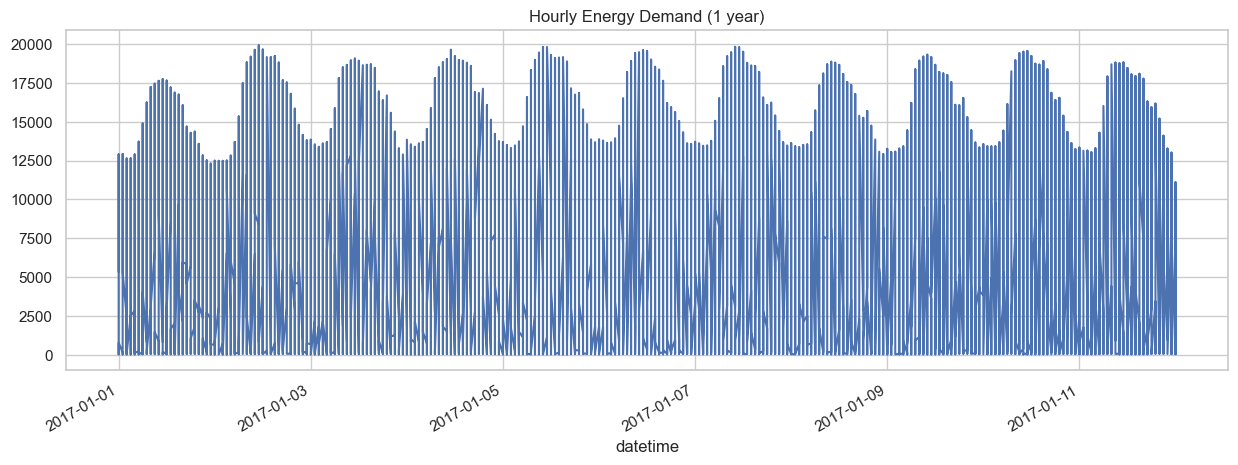

In [37]:
# Plot 52 weeks = 1 year of data to see the daily rhythm
df['demand_mw'].iloc[:24*7*52].plot(figsize=(15, 5), title='Hourly Energy Demand (1 year)')
plt.show()

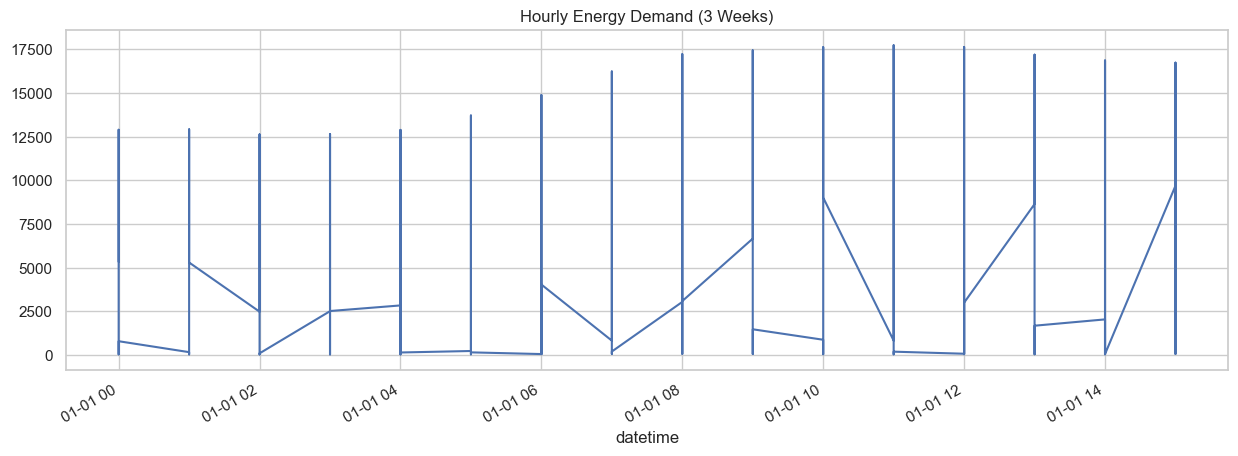

In [38]:
# Plot 3 weeks of data to see the daily rhythm
df['demand_mw'].iloc[:24*21].plot(figsize=(15, 5), title='Hourly Energy Demand (3 Weeks)')
plt.show()

## Correlation

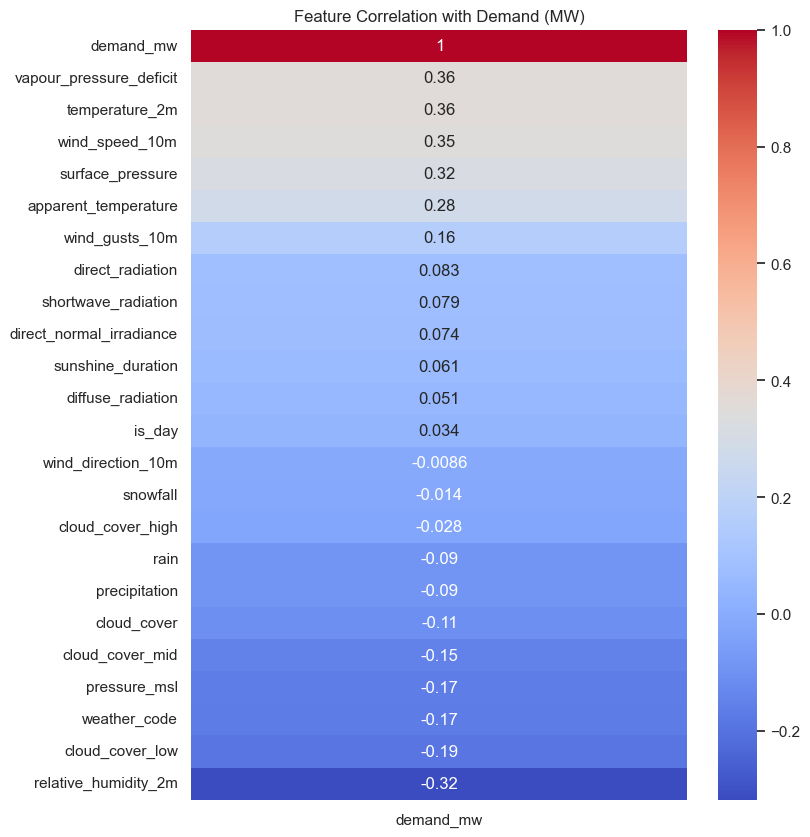

In [39]:
# Correlation Heatmap focusing on the target
plt.figure(figsize=(8, 10))
correlations = df.corr()[['demand_mw']].sort_values(by='demand_mw', ascending=False)
sns.heatmap(correlations, annot=True, cmap='coolwarm')
plt.title("Feature Correlation with Demand (MW)")
plt.show()

C:\Users\dipan\AppData\Local\Temp\ipykernel_22064\2682321273.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=daily_avg.index, y=daily_avg.values, palette="viridis")


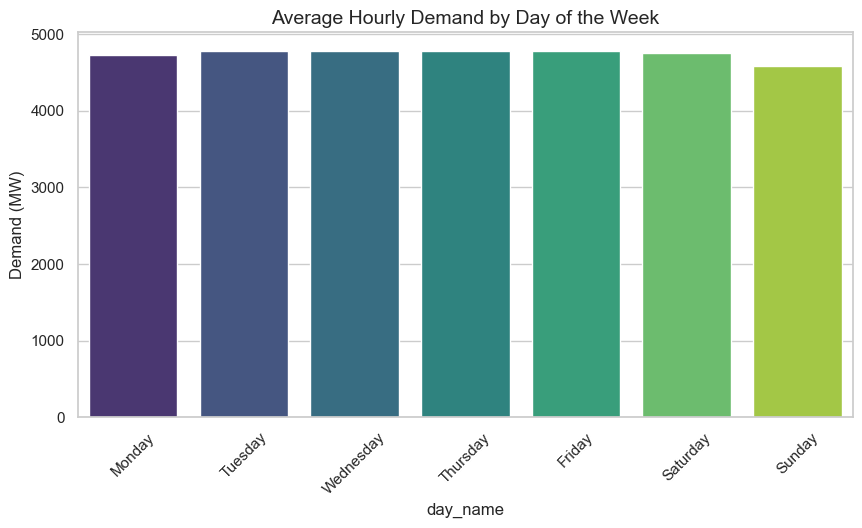

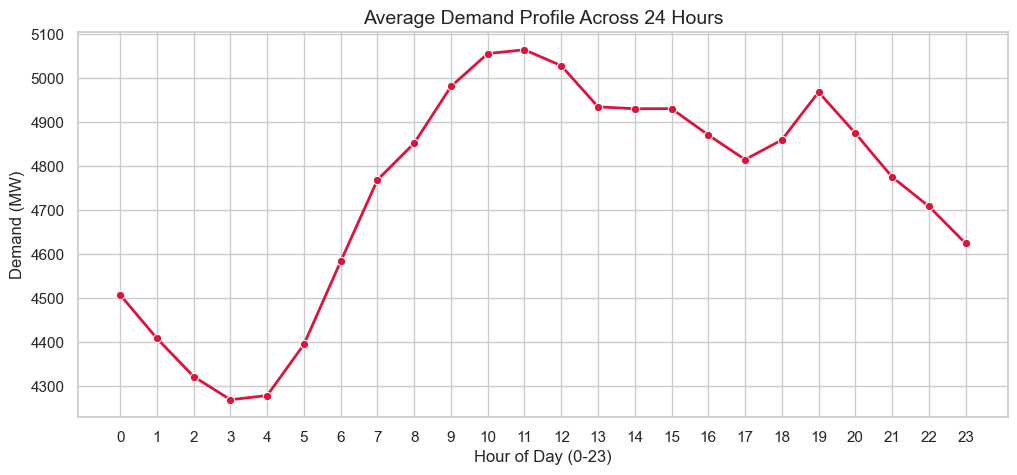

C:\Users\dipan\AppData\Local\Temp\ipykernel_22064\2682321273.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=yearly_avg.index, y=yearly_avg.values, palette="mako")


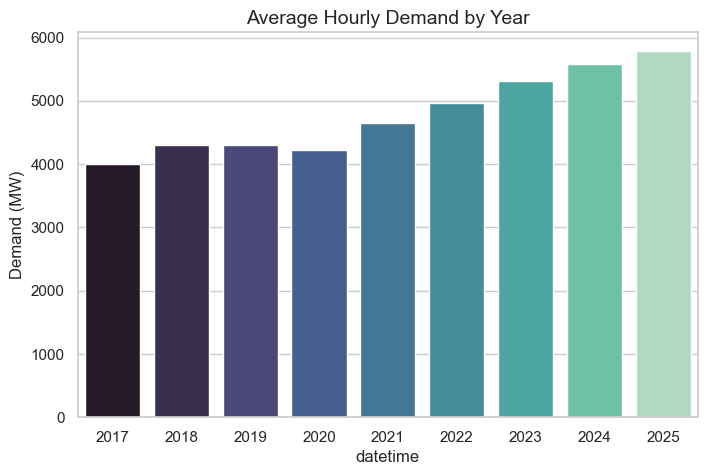

In [46]:
import calendar

sns.set_theme(style="whitegrid")

# 1. Average Energy Demand by Day of the Week
plt.figure(figsize=(10, 5))
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Map 0-6 to actual day names
df['day_name'] = df['day_of_week'].apply(lambda x: calendar.day_name[x])
daily_avg = df.groupby('day_name')['demand_mw'].mean().reindex(day_order)

sns.barplot(x=daily_avg.index, y=daily_avg.values, palette="viridis")
plt.title('Average Hourly Demand by Day of the Week', fontsize=14)
plt.ylabel('Demand (MW)')
plt.xticks(rotation=45)
plt.show()

# 2. Average Energy Demand by Hour of the Day
plt.figure(figsize=(12, 5))
hourly_avg = df.groupby('hour')['demand_mw'].mean()
sns.lineplot(x=hourly_avg.index, y=hourly_avg.values, marker='o', color='crimson', linewidth=2)
plt.title('Average Demand Profile Across 24 Hours', fontsize=14)
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Demand (MW)')
plt.xticks(range(0, 24))
plt.show()

# 3. Year-over-Year Demand Growth (Assuming you have multiple years)
plt.figure(figsize=(8, 5))
yearly_avg = df.groupby(df.index.year)['demand_mw'].mean()
sns.barplot(x=yearly_avg.index, y=yearly_avg.values, palette="mako")
plt.title('Average Hourly Demand by Year', fontsize=14)
plt.ylabel('Demand (MW)')
plt.show()

### hour vs day

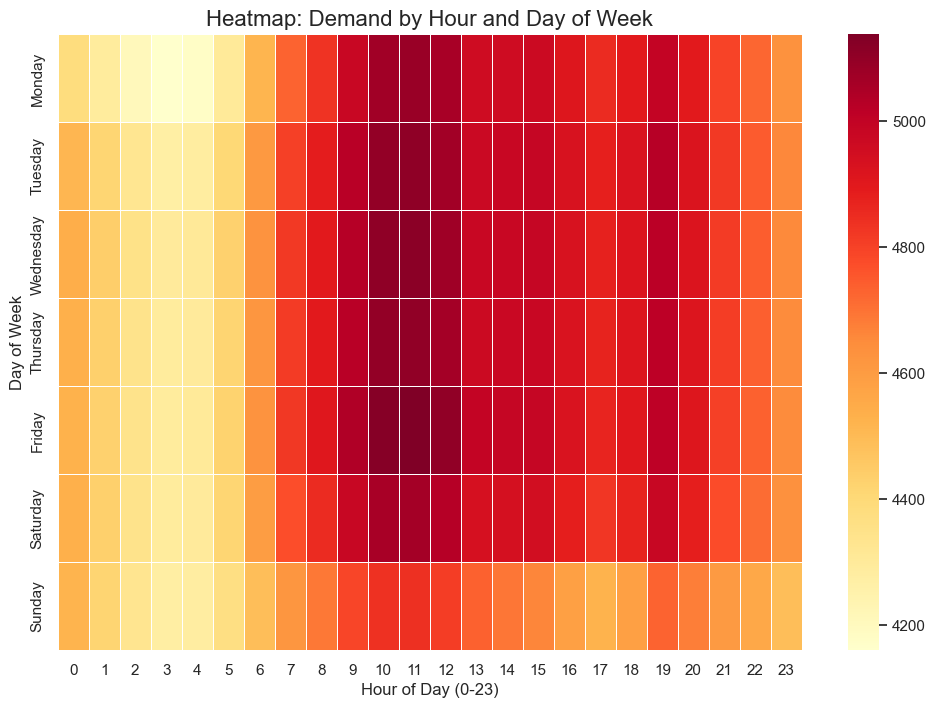

In [ ]:
plt.figure(figsize=(12, 8))
# Create a pivot table: Rows = Day of Week, Columns = Hour, Values = Average Demand
heatmap_data = df.pivot_table(values='demand_mw', index='day_name', columns='hour', aggfunc='mean')
heatmap_data = heatmap_data.reindex(day_order) # Keep Monday-Sunday order

sns.heatmap(heatmap_data, cmap="YlOrRd", linewidths=.5, annot=False)
plt.title('Heatmap: Demand by Hour and Day of Week', fontsize=16)
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Day of Week')
plt.show()

Duplicate timestamps found: 0


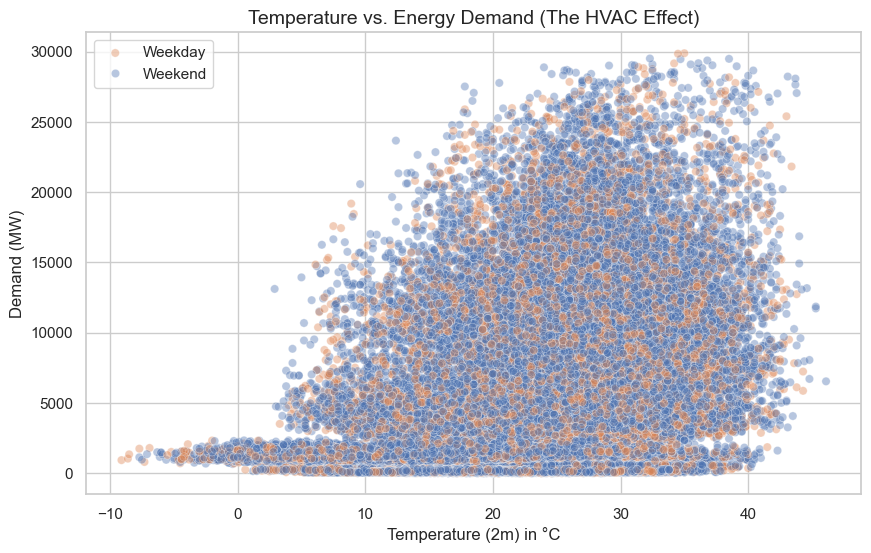

In [ ]:
# 1. Check exactly how many duplicate timestamps exist
print(f"Duplicate timestamps found: {df.index.duplicated().sum()}")

# 2. Drop the duplicates, keeping the first occurrence
temp = df[~df.index.duplicated(keep='first')]

# 3. Now run the plot again!
plt.figure(figsize=(10, 6))
sns.scatterplot(x='temperature_2m', y='demand_mw', hue='is_weekend', data=temp, alpha=0.4, palette='deep')
plt.title('Temperature vs. Energy Demand (The HVAC Effect)', fontsize=14)
plt.xlabel('Temperature (2m) in °C')
plt.ylabel('Demand (MW)')
plt.legend(['Weekday', 'Weekend'])
plt.show()

## Feature Engineering

In [11]:
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek
df['month'] = df.index.month
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

In [12]:
# Cyclical encoding for Hour (24 hours)
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

# Cyclical encoding for Month (12 months)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# You can drop the raw 'hour' and 'month' columns now if using linear models, 
# but keep them if using Tree-based models (LightGBM/XGBoost) as they handle both well.

In [13]:
# How much was the demand exactly 24 hours ago?
df['demand_lag_24h'] = df['demand_mw'].shift(24)

# How much was the demand exactly 24 hours ago?
df['demand_lag_48h'] = df['demand_mw'].shift(48)

# How much was the demand exactly 24 hours ago?
df['demand_lag_72h'] = df['demand_mw'].shift(72)

# How much was the demand exactly 1 week ago? (168 hours)
df['demand_lag_1w'] = df['demand_mw'].shift(168)

# How much was the demand exactly 2 week ago? (168 hours)
df['demand_lag_2w'] = df['demand_mw'].shift(168*2)

# How much was the demand exactly 1 month ago? (28 days)
df['demand_lag_4w'] = df['demand_mw'].shift(24*7*4)

In [14]:
# 24-hour moving average of demand
df['demand_rolling_mean_24h'] = df['demand_mw'].shift(1).rolling(window=24).mean()

# 24-hour moving average of temperature (captures heatwaves/cold spells)
df['temp_rolling_mean_24h'] = df['temperature_2m'].shift(1).rolling(window=24).mean()

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2629392 entries, 2017-01-01 00:00:00 to 2025-12-31 23:00:00
Data columns (total 40 columns):
 #   Column                    Dtype  
---  ------                    -----  
 0   temperature_2m            float64
 1   relative_humidity_2m      float64
 2   apparent_temperature      float64
 3   precipitation             float64
 4   rain                      float64
 5   snowfall                  float64
 6   weather_code              float64
 7   pressure_msl              float64
 8   surface_pressure          float64
 9   cloud_cover               float64
 10  cloud_cover_low           float64
 11  cloud_cover_mid           float64
 12  cloud_cover_high          float64
 13  vapour_pressure_deficit   float64
 14  wind_speed_10m            float64
 15  wind_direction_10m        float64
 16  wind_gusts_10m            float64
 17  shortwave_radiation       float64
 18  direct_radiation          float64
 19  diffuse_radiation         floa

## getting data ready for model

In [ ]:
# 1. Fix the "Zero" Demand Anomalies
# Replace exact 0s with NaN, then use time-based interpolation to estimate what the demand actually was
# df['demand_mw'] = df['demand_mw'].replace(0.0, np.nan)
# df['demand_mw'] = df['demand_mw'].interpolate(method='time')

Final Dataset Shape ready for XGBoost: (3471, 34)


In [16]:
# 2. Add "Heatwave Memory" & Long-Term Trend Baselines
# Rolling Max/Min Temp over the last 24 hours
df['temp_rolling_max_24h'] = df['temperature_2m'].shift(1).rolling(window=24).max()
df['temp_rolling_min_24h'] = df['temperature_2m'].shift(1).rolling(window=24).min()

# 7-Day Rolling Mean of Demand (Crucial for XGBoost to understand the current "Macro Trend")
df['demand_rolling_mean_168h'] = df['demand_mw'].shift(1).rolling(window=168).mean()

In [18]:
# 3. Drop the Noise & Redundant Features
cols_to_drop = [
    'snowfall', 
    'wind_direction_10m', 
    'day_name', 
    'cloud_cover_high', 
    'cloud_cover_mid', 
    'cloud_cover_low',
    'diffuse_radiation', 
    'direct_normal_irradiance', 
    'shortwave_radiation', 
    'direct_radiation',
    'is_day' # Often redundant with shortwave radiation / hour
]

# Only drop if they exist in the dataframe to avoid errors
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

In [ ]:
# 4. Final Cleanup: Drop all rows with NaNs created by our massive 4-week (672 hour) lags
new = df.dropna()

print(f"Final Dataset Shape ready for XGBoost: {df.shape}")

Final Dataset Shape ready for XGBoost: (3434, 33)


In [64]:
(df['hour'] == 0).any()

np.True_

In [67]:
df.isna().sum()

temperature_2m                0
relative_humidity_2m          0
apparent_temperature          0
precipitation                 0
rain                          0
weather_code                  0
pressure_msl                  0
surface_pressure              0
cloud_cover                   0
vapour_pressure_deficit       0
wind_speed_10m                0
wind_gusts_10m                0
sunshine_duration             0
demand_mw                     0
hour                          0
day_of_week                   0
month                         0
is_weekend                    0
hour_sin                      0
hour_cos                      0
month_sin                     0
month_cos                     0
demand_lag_24h               24
demand_lag_168h               0
demand_rolling_mean_24h      24
temp_rolling_mean_24h        24
demand_lag_48h               48
demand_lag_72h               72
demand_lag_1w               168
demand_lag_4w               672
temp_rolling_max_24h         24
temp_rol

In [19]:
df.shape

(2629392, 33)